# Makale yöntem denetimi ve düzeltilmiş deneyler

Bu defter, makalenin Bölüm 3, Denklem 10–13 ve Algoritma 1 tariflerini
uygulamayla karşılaştırır. Dördüncü defter önceki sürümün tarihsel
sonuçlarını korur. Buradaki yeni eğitimler eski ağırlıkların üzerine yazılmaz.

Çekirdek yöntem farkları düzeltildi. Model kapasitesi ve değerlendirme
düzenindeki korunan farklar nedeniyle çalışma ölçekli yöntem uygulamasıdır;
makalenin bütün deneylerinin birebir tekrarı olarak sunulmaz.

In [1]:
from pathlib import Path
import inspect
import json
import os
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image, Code

ROOT = Path.cwd().resolve()
if not (ROOT / "src/kt_project").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".runtime/matplotlib"))
os.environ.setdefault("PYTHONUTF8", "1")
RUN = ROOT / "outputs/main/paper_alignment_v2"
def read(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))
def run_script(name):
    completed = subprocess.run([sys.executable, str(ROOT / "scripts" / name)], cwd=ROOT,
        capture_output=True, text=True, encoding="utf-8", errors="replace")
    print(completed.stdout)
    if completed.returncode:
        print(completed.stderr)
    completed.check_returncode()
status = read(RUN / "status.json")
assert status["status"] == "complete", "Eğitim tamamlanmadan sonuç defteri çalıştırılmaz."
results, config = read(RUN / "results.json"), read(RUN / "config.json")
audit = read(ROOT / "outputs/method_audit/audit_matrix.json")
display(pd.DataFrame(audit["matrix"]))

,component,paper_location,legacy,corrected,decision
0,Dikkat eğitimde,"3.2,3.4; s.8,13–14","LKM nedensel, PromEnc iki yönlü",İki modül de iki yönlü,Düzeltildi
1,Dikkat tahminde,3.5; s.14,"LKM nedensel, PromEnc iki yönlü",İki modül de nedensel,Düzeltildi
2,Şablon sırası,Denklem10–13; Şekil6–7,Pseudo tokenlar başta; maske sonda,"e,c,MASK_r,T ve MASK_e,c,r,T",Düzeltildi; başta prompt düzeni ayrı kontrol
3,Çıktı konumu,3.4–3.5; s.14,Daima son konum,"Cevapta şablonun 2., soruda 0. indisi",Düzeltildi; indisler sıfır tabanlı
4,Şablonun soru temsili,Denklem12–13,Soru temsiline hedef zorluğu ekleniyor,"Şablonda e,c,r; geçmişte zorluk korunuyor",Düzeltildi
5,FBO negatifleri,3.2; s.9,Başka öğrencinin ikinci yarısı,Bütün yarım parça havuzundan özgün doğru çift ...,Düzeltildi
6,RTM bozulması,3.2; s.9,Seçilen konumda soru ve cevap bağımsız bozuluyor,Konum başına ortak 80/10/10 işlemi; eşlenmiş s...,Konum temelli tarifin açık uygulaması
7,Kayıp ölçekleme,Denklem3–7,RTM token ortalaması ve FBO dizi ortalaması to...,Bütün kayıp toplamı aynı dizi sayısına bölünüyor,Denklem toplam ölçeği uygulandı; yazarın kod ö...
8,BERT katman düzeni,3.2; s.8–9,Ön normalizasyon ve son ek normalizasyon,BERT tarzı son normalizasyon; son ek norm yok,Düzeltildi
9,"En uzun geçmiş, dropout, optimizer",4.2; s.18,"128,0.2,AdamW","200,0.4,Adam",Düzeltildi


## Düzeltilen şablon ve dikkat

Eğitimde iki modül de iki yönlü; tahminde ikisi de nedenseldir. Her hedef
ayrı bir geçmiş önekiyle işlendiği için iki yönlü eğitimde hedefin gerçek
cevabı girdi olmaz. KPT şablonu `e,c,MASK_r,T`; KMPT yardımcı şablonu
`MASK_e,c,r,T` sırasındadır. Çıktı son tokendan değil ilgili maskeden okunur.
Şablonda hedef soru zorluğu eklenmez; geçmiş etkileşimlerinde zorluk korunur.

In [2]:
from kt_project.plkt_models import PaperPromptEncoder, PaperKnowledgeTracer, PaperLKM
from kt_project.plkt_sequences import PaperPretrainingDataset
display(Code(inspect.getsource(PaperPromptEncoder.forward), language="python"))
display(Code(inspect.getsource(PaperKnowledgeTracer.encode_prediction), language="python"))

def forward(self, question, concepts, response, auxiliary=False, causal=False):
        soft = self.soft_prompt.unsqueeze(0).expand(len(question), -1, -1)
        # Eq.12: e,c,MASK_r,prompt; Eq.13: MASK_e,c,r,prompt.
        if self.layout == "paper_tail":
            tokens = torch.cat([torch.stack([question, concepts, response], dim=1), soft], dim=1)
            mask_index = 0 if auxiliary else 2
        else:
            tail = torch.stack([concepts, response, question] if auxiliary else [question, concepts, response], dim=1)
            tokens = torch.cat([soft, tail], dim=1)
            mask_index = tokens.shape[1]-1
        positions = torch.arange(tokens.shape[1], device=tokens.device)
        tokens = self.norm(tokens+self.position(positions))
        mask = torch.triu(torch.ones(tokens.shape[1], tokens.shape[1], dtype=torch.bool, device=tokens.device), 1) if causal else None
        return self.encoder(tokens, mask=mask), mask_index

def encode_prediction(self, batch, auxiliary=False):
        if auxiliary and (self.method != "kmpt" or not self.training):
            raise ValueError("Yardımcı şablon yalnızca KMPT eğitimi içindir.")
        question = batch["target_question"]
        response = batch["label"].long() if auxiliary else torch.full_like(question, RESPONSE_MASK)
        if auxiliary:
            question = torch.full_like(question, QUESTION_MASK)
        # Each batch is already a prefix ending immediately BEFORE its target.
        # Bidirectional attention over this observed prefix does not expose future labels.
        history = self.lkm.interaction_embeddings(batch["history_question"], batch["history_skills"],
                                                   batch["history_response"], batch["history_difficulty"])
        causal = not self.training
        if self.method == "baseline":
            template = self.lkm.interaction_embeddings(question, batch["target_skills"], response,
                                                        batch["target_difficulty"]).unsqueeze(1)
            local_index = 0
        else:
            # Eq.12–13 specify e,c,r embeddings in the template; target difficulty
            # is not added to e. History difficulty remains in Eq.2 embeddings.
            template, local_index = self.prompt_encoder(self.lkm.question_embedding(question),
                self.lkm.concept_embeddings(batch["target_skills"]), self.lkm.response_embedding(response),
                auxiliary=auxiliary, causal=causal)
        batch_size, width = history.shape[:2]
        cls = self.lkm.special_embedding.weight[1].expand(batch_size, 1, -1)
        embeddings = torch.cat([cls, history, template], dim=1)
        padding = torch.cat([torch.zeros(batch_size, 1, device=history.device, dtype=torch.bool),
                              batch["history_padding"],
                              torch.zeros(batch_size, template.shape[1], device=history.device, dtype=torch.bool)], dim=1)
        lengths = (~batch["history_padding"]).sum(dim=1)
        positions = torch.cat([torch.zeros(batch_size, 1, dtype=torch.long, device=history.device),
            torch.arange(1, width+1, device=history.device).expand(batch_size, -1),
            lengths[:, None]+torch.arange(1, template.shape[1]+1, device=history.device)], dim=1)
        hidden = self.lkm.encode(embeddings, padding, positions, causal=causal)
        return hidden[:, 1+width+local_index]

## Ön eğitim, ölçekleme ve parametre güncellemesi

FBO negatifleri bütün yarım parça havuzundan, özgün doğru çift hariç
seçilir. RTM seçilmiş konumda soru ve cevap için ortak 80/10/10 bozulması
uygular. Maskeli konumların kayıpları ile FBO kaybı aynı dizi sayısına göre
ölçeklenir. LKM BERT tarzı son normalizasyon kullanır.

Algoritma 1 adım 24 LKM'nin uyarlanmasını tarif eder; açık bir dondurma
zorunluluğu yoktur. LKM ve promptların birlikte eğitilmesi korunmuştur.

In [3]:
display(Code(inspect.getsource(PaperLKM.pretraining_loss), language="python"))
display(pd.Series(config["model"]))
display(pd.Series(config["retained_differences"], name="Korunan deney farkları"))
stopping = []
for seed in config["seeds"]:
    stopping.append({"seed": seed, **read(RUN / f"seed_{seed}/pretraining_stopping.json")})
display(pd.DataFrame(stopping))

def pretraining_loss(self, batch):
        embeddings = self.interaction_embeddings(batch["question"], batch["skills"],
                                                 batch["response"], batch["difficulty"])
        embeddings = torch.where(batch["special"].gt(0).unsqueeze(-1),
                                 self.special_embedding(batch["special"]), embeddings)
        hidden = self.encode(embeddings, batch["padding"], causal=False)
        chosen = batch["question_labels"].ne(-100)
        assert torch.equal(chosen, batch["response_labels"].ne(-100))
        q_losses = F.cross_entropy(self.question_head(hidden[chosen]),
                                  batch["question_labels"][chosen], reduction="none")
        r_losses = F.binary_cross_entropy_with_logits(self.response_head(hidden[chosen]).squeeze(-1),
                                                       batch["response_labels"][chosen].float(), reduction="none")
        fbo = F.binary_cross_entropy_with_logits(self.order_head(hidden[:, 0]).squeeze(-1), batch["fbo_label"])
        # Eq. 3–7 sum over masked positions and sequences. Divide the WHOLE sum
        # by sequence count; separately token-averaging RTM changes its FBO weight.
        batch_size = len(hidden)
        q_sum, r_sum = q_losses.sum()/batch_size, r_losses.sum()/batch_size
        return q_sum+r_sum+fbo, {"question_loss": q_sum.detach(), "response_loss": r_sum.detach(),
                               "order_loss": fbo.detach(), "question_token_mean": q_losses.mean().detach(),
                               "response_token_mean": r_losses.mean().detach()}

hidden_size         128.0
layers                2.0
attention_heads       4.0
feedforward_size    512.0
max_history         200.0
prompt_length         8.0
prompt_layers         1.0
dropout               0.4
dtype: float64

0    scaled LKM 2 layers/128 hidden/4 heads and Pro...
1    downstream batch 512 rather than 64 for local ...
2    student-disjoint 70/15/15 holdout rather than ...
3    one true multi-concept event retained with mea...
4    difficulty calculated on training only to avoi...
5    bounded training budget with recorded stopping...
6    one dataset and three initialization seeds rat...
Name: Korunan deney farkları, dtype: str

,seed,epochs,best_epoch,criterion,reason
0,17,30,30,"training objective relative improvement, not h...",epoch_budget_reached
1,42,30,30,"training objective relative improvement, not h...",epoch_budget_reached
2,2026,30,30,"training objective relative improvement, not h...",epoch_budget_reached


## Makale tarifindeki dikkat gerilimi için ayrı kontrol

Sondaki pseudo tokenlar, katı nedensellikte önceki maskeli cevabı
etkileyemez. Bu, makalenin sırası ve Bölüm 3.5 birlikte okunduğunda çıkan
sonuçtur; yazar kodunun incelendiği anlamına gelmez. Ayrı KMPT prefix
kontrolü yalnızca şablon yerleşimini değiştirir. Eğitimde prompt gradyanı
bulunması, aynı promptun tahminde erişilebilir olduğunu kanıtlamaz.

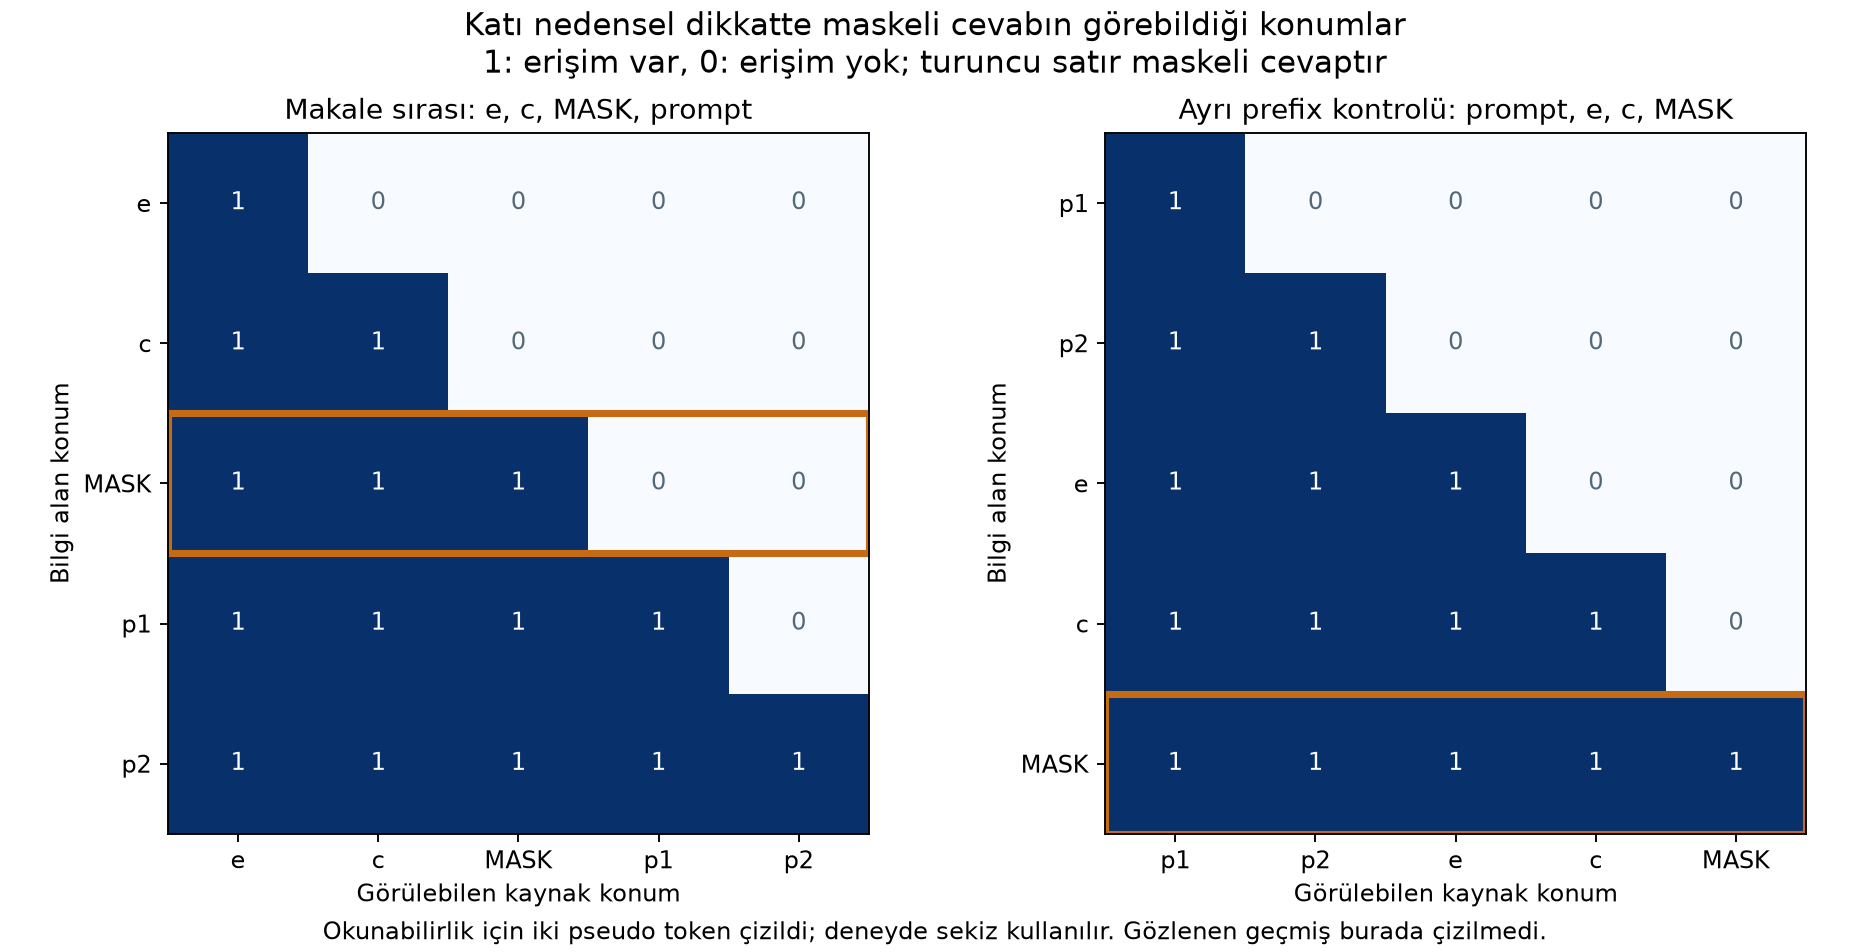

{"conditions": 12, "prototype_seed": 17, "summary": {"baseline": {"auc": {"mean": 0.7585230093621611, "sample_sd": 0.0032407732152768902}, "accuracy": {"mean": 0.7258749897672896, "sample_sd": 0.0030523968727741136}, "bce": {"mean": 0.5787669015301732, "sample_sd": 0.00506718171074959}}, "kpt": {"auc": {"mean": 0.7489216330547873, "sample_sd": 0.0009583915274552384}, "accuracy": {"mean": 0.7146897070095927, "sample_sd": 0.007715285785858238}, "bce": {"mean": 0.5595562244678249, "sample_sd": 0.009845846393985204}}, "kmpt": {"auc": {"mean": 0.7521846540878728, "sample_sd": 0.004331260228848474}, "accuracy": {"mean": 0.7227121519948203, "sample_sd": 0.002880302457702681}, "bce": {"mean": 0.5522383488127788, "sample_sd": 0.0034709058307586804}}, "kmpt_prefix": {"auc": {"mean": 0.7568854598873059, "sample_sd": 0.0026867714881138602}, "accuracy": {"mean": 0.7246842743705953, "sample_sd": 0.002604615509493289}, "bce": {"mean": 0.546023663291878, "sample_sd": 0.0036429589327066705}}}}
{"phase"

,seed,variant,samples,training_soft_prompt_gradient_l1,prediction_max_probability_delta_after_soft_prompt_perturbation,inference_attention,inference_dtype
0,17,kpt,16,7.715868,0.000000,strict causal in both encoders,float32
1,17,kmpt,16,7.068197,0.000000,strict causal in both encoders,float32
2,17,kmpt_prefix,16,8.255409,0.263285,strict causal in both encoders,float32
3,42,kpt,16,8.210534,0.000000,strict causal in both encoders,float32
4,42,kmpt,16,8.036043,0.000000,strict causal in both encoders,float32
5,42,kmpt_prefix,16,6.836374,0.075992,strict causal in both encoders,float32
6,2026,kpt,16,3.998070,0.000000,strict causal in both encoders,float32
7,2026,kmpt,16,10.704840,0.000000,strict causal in both encoders,float32
8,2026,kmpt_prefix,16,8.888853,0.114123,strict causal in both encoders,float32


In [4]:
display(Image(filename=str(ROOT / "outputs/figures/paper_prompt_visibility.png")))
run_script("analyze_paper_alignment.py")
diagnostic = read(RUN / "analysis/prompt_sensitivity.json")
display(pd.DataFrame(diagnostic))

## Aynı hedeflerde üç başlangıçlı yeni sonuçlar

Ana karşılaştırma promptsuz, KPT ve KMPT'dir. Prefix ayrı yerleşim
kontrolüdür. Bütün koşullar aynı başlangıç içinde aynı yeni ön eğitimden
başlar. Dönemler yalnızca doğrulama BCE değeriyle seçilir; tüm eğitimler
bittikten sonra kontrol noktaları kilitlenir ve test hesaplanır.

,Koşul,AUC ortalama,AUC örnek SS,Doğruluk ortalama %,BCE ortalama
0,baseline,0.7585,0.0032,72.5875,0.5788
1,kpt,0.7489,0.0010,71.4690,0.5596
2,kmpt,0.7522,0.0043,72.2712,0.5522
3,kmpt_prefix,0.7569,0.0027,72.4684,0.5460


,seed,variant,best_epoch,validation_BCE,test_AUC,test_accuracy
0,17,baseline,1,0.593221,0.759476,0.726575
1,17,kpt,1,0.578715,0.750004,0.705878
2,17,kmpt,1,0.554019,0.752359,0.722668
3,17,kmpt_prefix,2,0.548882,0.759682,0.726999
4,42,baseline,1,0.583005,0.761181,0.728517
5,42,kpt,1,0.559146,0.748580,0.717957
6,42,kmpt,1,0.559507,0.747769,0.719854
7,42,kmpt_prefix,2,0.557492,0.756650,0.725190
8,2026,baseline,1,0.587247,0.754913,0.722534
9,2026,kpt,1,0.556663,0.748181,0.720234


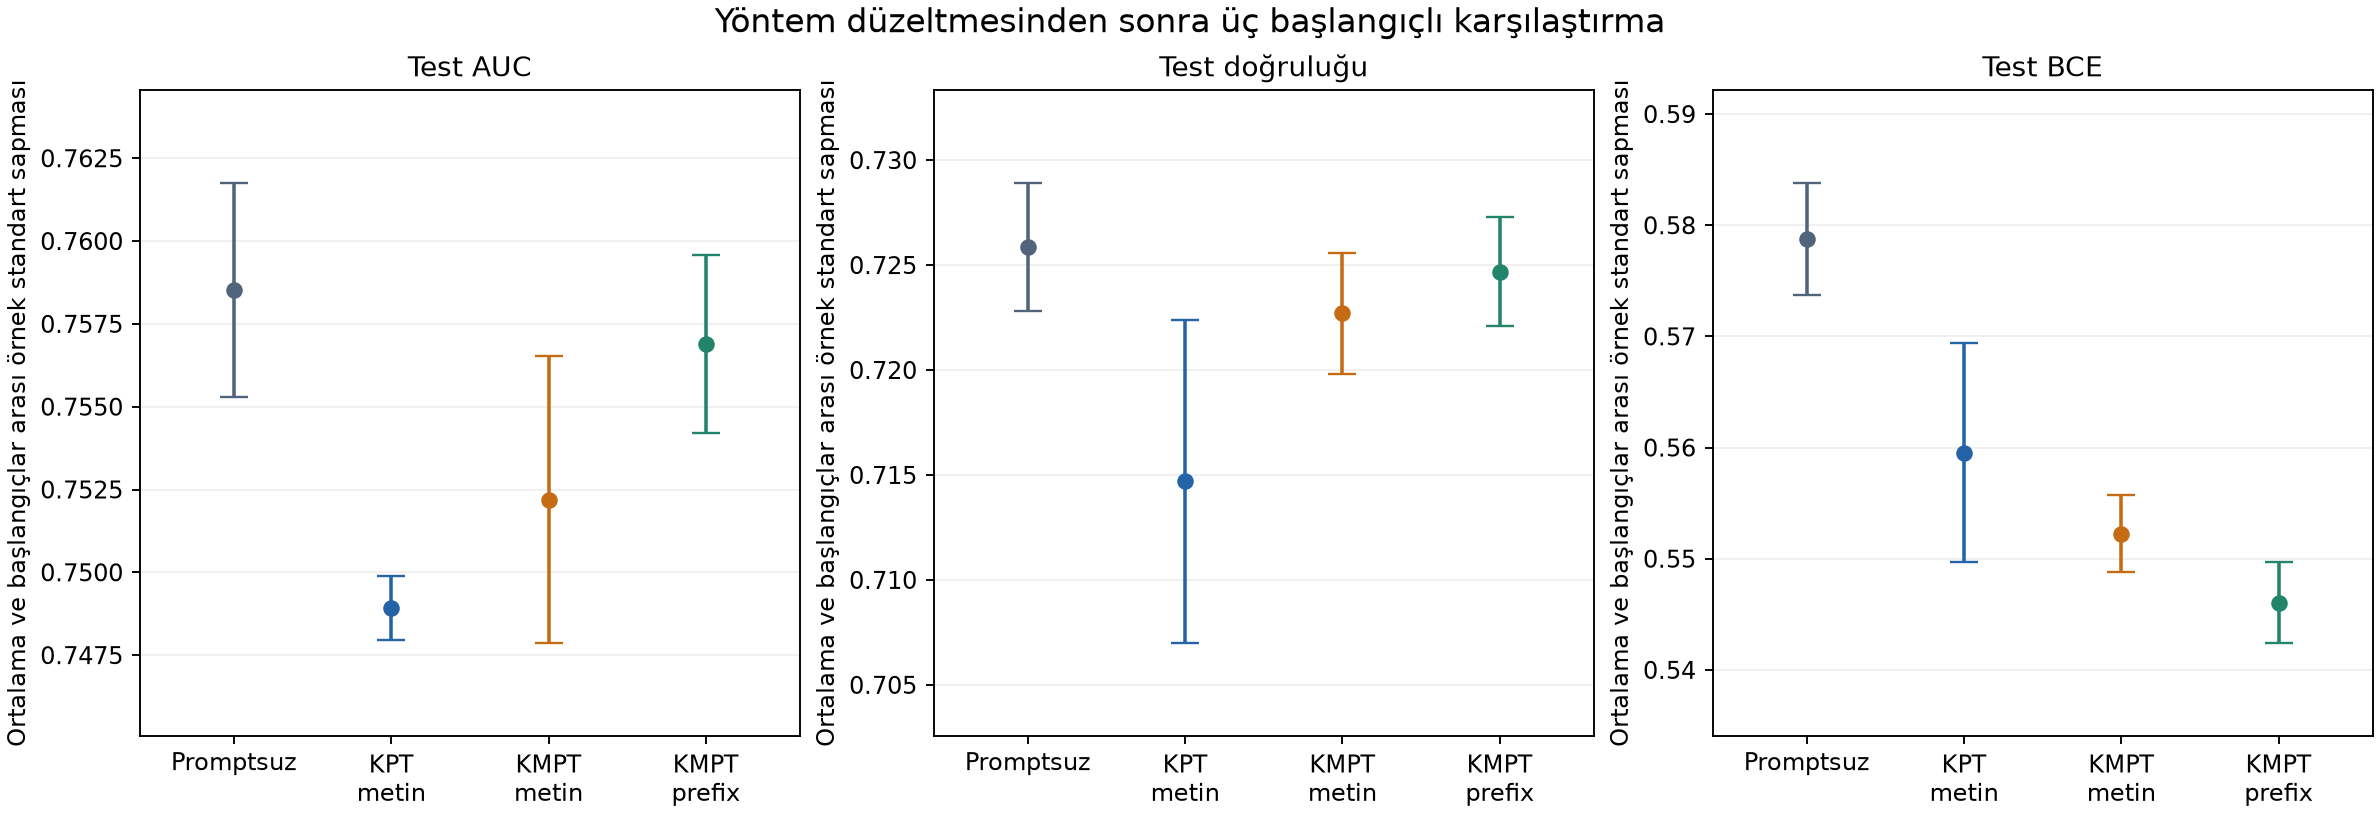

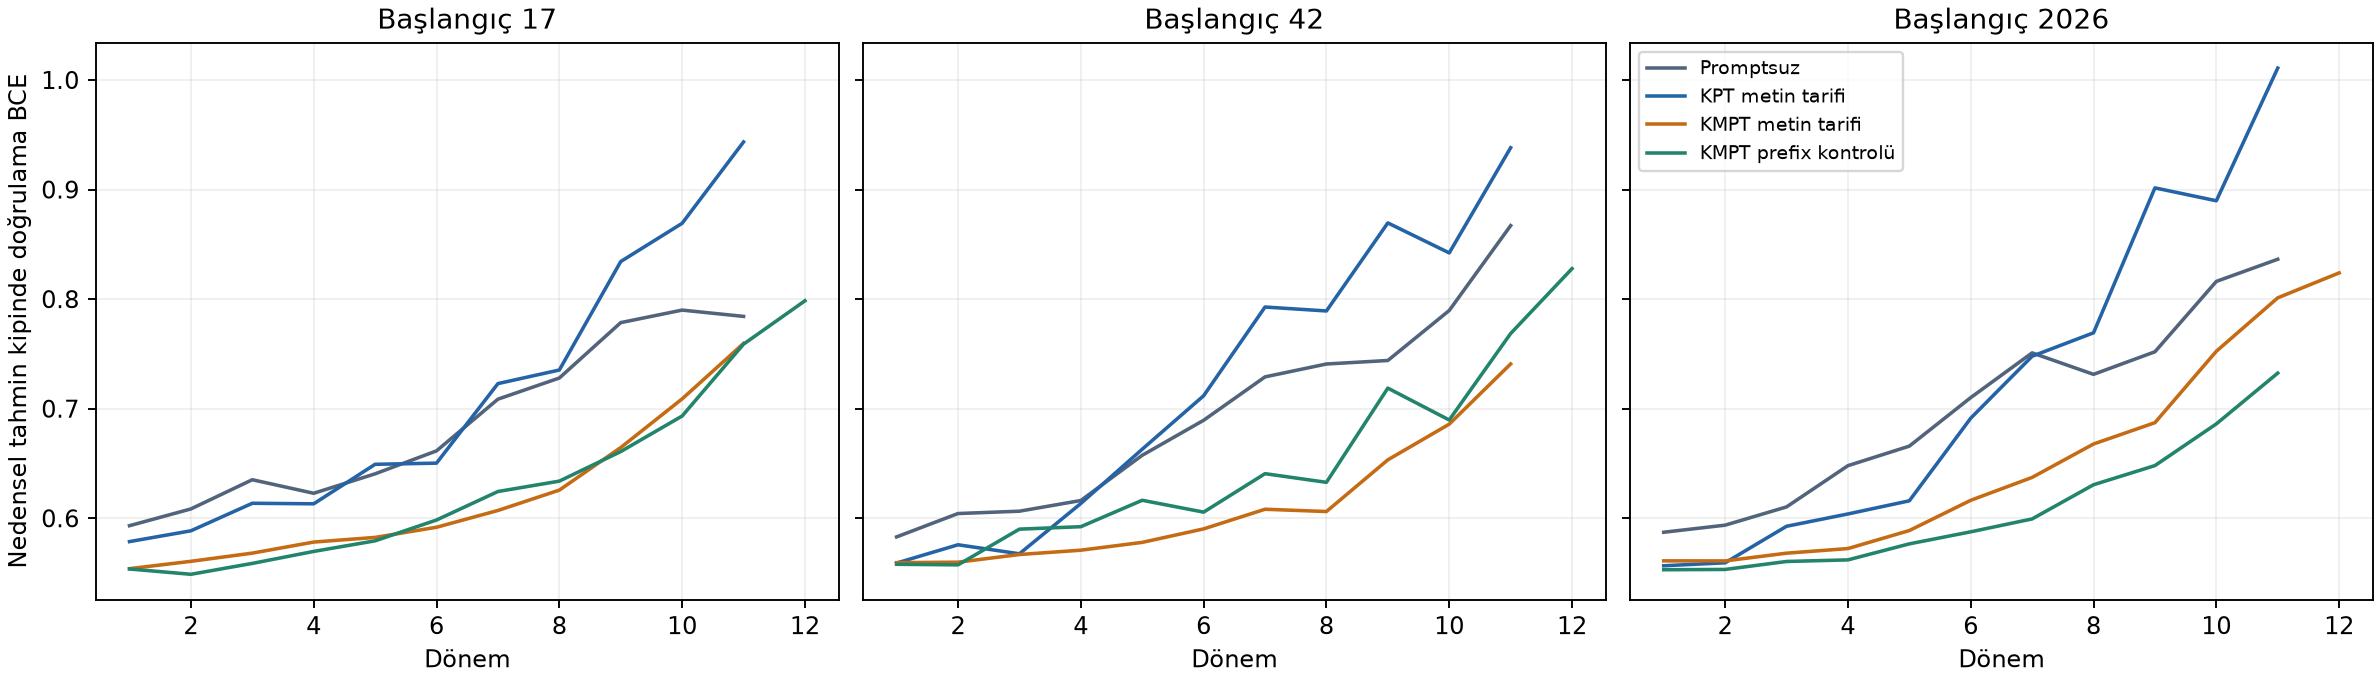

In [5]:
summary = read(RUN / "analysis/summary.json")
rows = []
for variant, metrics in summary.items():
    rows.append({"Koşul": variant,
        "AUC ortalama": metrics["auc"]["mean"], "AUC örnek SS": metrics["auc"]["sample_sd"],
        "Doğruluk ortalama %": 100*metrics["accuracy"]["mean"],
        "BCE ortalama": metrics["bce"]["mean"]})
display(pd.DataFrame(rows).round(4))
display(pd.DataFrame([{"seed": row["seed"], "variant": row["variant"],
    "best_epoch": row["best_epoch"], "validation_BCE": row["validation"]["bce"],
    "test_AUC": row["test"]["auc"], "test_accuracy": row["test"]["accuracy"]} for row in results["runs"]]))
display(Image(filename=str(ROOT / "outputs/figures/paper_alignment_comparison.png")))
display(Image(filename=str(ROOT / "outputs/figures/paper_alignment_validation.png")))

Sabit ayrımın test sonuçları önceki sürümde zaten görülmüştür. Yeni deney,
tamamen dokunulmamış yeni bir doğrulayıcı test olarak sunulmaz. Yöntem
düzeltmeleri eski testte üstün sonuç elde etmek için seçilmemiştir. Eski
ve yeni sürüm birden çok bileşende değiştiğinden başarı farkı tek bir
düzeltmeye atfedilemez. Üç başlangıçtaki standart sapma güven aralığı değildir.

## Güncel öğrenci takibine bağlantı ve denetim

Ek kontrolde aynı hedefin bilinen şablon tokenları tek zaman bloğu
kabul edilir. Geçmiş sonraki olayları göremez; aynı hedef bloğunda
iki yönlü erişim vardır. Bu, doğrulanmış yazar kodu değil açık bir maske
yorumudur. Aynı ağırlıklarda altı ek tahmin değerlendirmesi yapılır;
yeni eğitim veya bu politikaya özel dönem seçimi yapılmaz. Prototipte
bu blok politikası testten önce belirlenmiş, KMPT başlangıcı yalnızca
blok doğrulama BCE değeriyle seçilmiştir.
Öğrenci göstergeleri, davranış grupları, yeniden oynatım
ve küçük etkileşim önerileri yeni ağırlıklarla yeniden üretilir. Eski
gösterim çıktıları arşivlenir. Beşinci, altıncı ve yedinci defter güncel
ağırlıkları kullanır.

In [6]:
interpretation = read(RUN / "interpretations/results.json")
display(pd.DataFrame([{"method": row["method"], "seed": row["seed"],
    "block_AUC": row["test"]["auc"], "strict_AUC": row["strict_test"]["auc"]}
    for row in interpretation["runs"]]))
print("Blok politikada prompt olasılık etkisi:", interpretation["selected_model_prompt_probability_delta"])
selection = read(RUN / "interpretations/prototype_selection.json")
display(pd.Series(selection))
integrity = read(RUN / "analysis/integrity.json")
display(pd.Series({key: value for key, value in integrity.items() if key != "checks"}))
if (ROOT / "configs/active_model.json").exists():
    active = read(ROOT / "configs/active_model.json")
    assert active["version"] == "paper_alignment_v2"
    replay = read(ROOT / "outputs/replay/session.json")
    patterns = read(ROOT / "outputs/patterns/metadata.json")
    assert replay["model_selection"]["checkpoint_sha256"] == selection["checkpoint_sha256"]
    assert patterns["checkpoint_sha256"] == selection["checkpoint_sha256"]
    assert patterns["inference_policy"] == selection["inference_policy"]
    print("Öğrenci takibi ve örüntü modeli güncel ağırlıklarla eşleşiyor.")

,method,seed,block_AUC,strict_AUC
0,kpt,17,0.754984,0.750004
1,kmpt,17,0.752237,0.752359
2,kpt,42,0.751419,0.748580
3,kmpt,42,0.748046,0.747769
4,kpt,2026,0.752380,0.748181
5,kmpt,2026,0.758719,0.756426


Blok politikada prompt olasılık etkisi: 0.22996896505355835


format                                                                plkt_method_v2
method                                                                          kmpt
variant                                                                         kmpt
layout                                                                    paper_tail
inference_policy                                              same_target_step_block
seed                                                                              17
best_epoch                                                                         1
validation_bce                                                              0.554962
criterion                          minimum block-policy validation BCE among thre...
checkpoint                         outputs/main/paper_alignment_v2/seed_17/kmpt_b...
checkpoint_sha256                  5f913ec2fd02e63b967eef93d52c3842260f65b1e7faf7...
inference_implementation_sha256    b04aebe91b6e065081736a9cfa605e

all_checks_passed                                                            True
conditions                                                                     12
same_test_targets                                                            True
test_targets                                                                44791
test_lock_verified                                                           True
common_pretraining_per_seed_verified                                         True
source_hashes_verified                                                       True
prefix_control_common_prompt_initialization_and_auxiliary_draws_verified     True
dtype: object

Öğrenci takibi ve örüntü modeli güncel ağırlıklarla eşleşiyor.


In [7]:
completed = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
    cwd=ROOT, capture_output=True, text=True, encoding="utf-8", errors="replace")
output = completed.stdout+completed.stderr
(ROOT / "outputs/validation/method_alignment_test_output.txt").write_text(output, encoding="utf-8")
print(output)
completed.check_returncode()

Davranış grubu için en az 5 cevap gerekir.
Önerilen mevcut soru: 104
A: izlenen beceriler arasında referans başarı tahmini en düşük olan beceri; sabit referans başarı tahmini %52.6. orta düzeyde zorlayıcı başarı hedefi. Seçilen soruda tahmin %52.6, hedef %65.
Davranış grubu için en az 5 cevap gerekir.
Önerilen mevcut soru: 104
A: izlenen beceriler arasında referans başarı tahmini en düşük olan beceri; sabit referans başarı tahmini %52.6. orta düzeyde zorlayıcı başarı hedefi. Seçilen soruda tahmin %52.6, hedef %65.
Davranış grubu için en az 5 cevap gerekir.
Önerilen mevcut soru: 110
A: izlenen beceriler arasında referans başarı tahmini en düşük olan beceri; sabit referans başarı tahmini %52.4. orta düzeyde zorlayıcı başarı hedefi. Seçilen soruda tahmin %52.5, hedef %65.
Davranış grubu için en az 5 cevap gerekir.
Önerilen mevcut soru: 110
A: izlenen beceriler arasında referans başarı tahmini en düşük olan beceri; sabit referans başarı tahmini %52.4. orta düzeyde zorlayıcı başarı hedefi. 

Kaynak: kullanıcı tarafından sağlanan Zhu, Qiu ve Zhou makalesi,
DOI 10.1007/s10618-026-01208-9. Özellikle sayfa 9–15 ve 18.
Madde bazlı açıklama `docs/makale_yontem_uyumu.md`, yeni sayısal sonuçlar
`docs/duzeltilmis_yontem_sonuclari.md` dosyalarındadır. Teslim raporu bu
denetimden sonra hazırlanır.